# Proyecto Análisis de Spam

**Integrantes:**
- [Nombre](mailto:correo@ejemplo.com)
- [Rebecca Shaday Castillo Ortega](mailto:rebeccashaday@gmail.com)
- [Kevin Vargas Flores](mailto:kevinvargasflores505@gmail.com)


## Descripción



# Etapa 1: Análisis, representación y baseline


## Dataset

In [1]:
#@title librerías etapa 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer as countvectorizer
from sklearn.naive_bayes import MultinomialNB as multinomialnb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

seed = 98
np.random.seed(seed)

# Importación del dataset

data = 'https://raw.githubusercontent.com/kao05/SpamAnalysis-TextMining/main/Data/SMSSpamCollection'

df = pd.read_csv(data, sep='\t', header=None, names=['label', 'message'])

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [2]:
df.shape

(5572, 2)

## Exploración del Corpus

label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: count, dtype: float64
nulos: 0
mensajes duplicados: 403


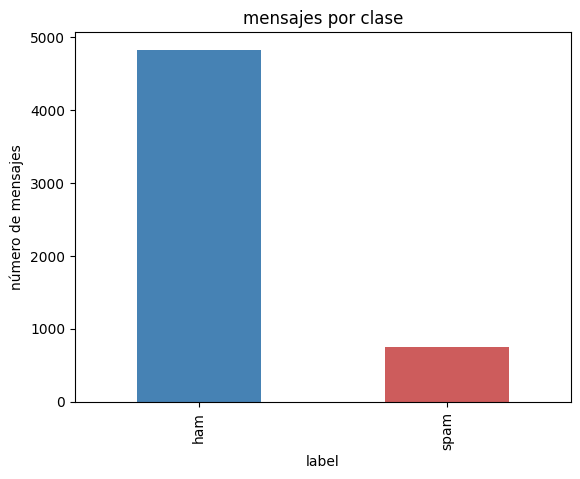

In [3]:
#@title desbalance, nulos y duplicados
conteo = df['label'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

print('nulos:', df.isnull().sum().sum())
print('mensajes duplicados:', df.duplicated(subset='message').sum())

conteo.plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('mensajes por clase')
plt.ylabel('número de mensajes')
plt.show()

In [4]:
#@title quitar duplicados antes de dividir y etiqueta numérica
df = df.drop_duplicates(subset='message', keep='first').reset_index(drop=True)
df['y'] = (df['label'] == 'spam').astype(int)

print('tamaño después de quitar duplicados:', df.shape)
print('proporción de spam:', round(df['y'].mean(), 4))

tamaño después de quitar duplicados: (5169, 3)
proporción de spam: 0.1263


label                   ham    spam
n_caracteres count  4516.00  653.00
             mean     70.91  137.70
             std      56.72   29.82
             min       2.00   13.00
             25%      34.00  132.00
             50%      53.00  148.00
             75%      91.00  157.00
             max     910.00  223.00
n_palabras   count  4516.00  653.00
             mean     14.24   23.74
             std      11.18    5.93
             min       1.00    2.00
             25%       7.00   22.00
             50%      11.00   25.00
             75%      19.00   28.00
             max     171.00   35.00


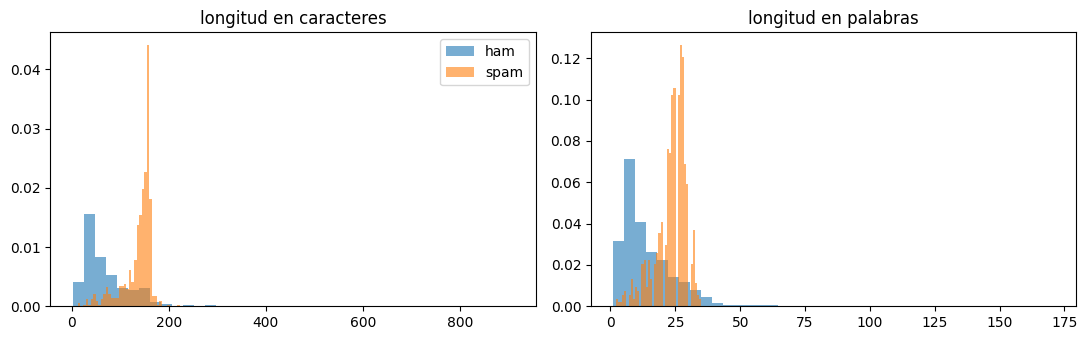

In [5]:
#@title logitudes por clase
df['n_caracteres'] = df['message'].str.len()
df['n_palabras'] = df['message'].str.split().str.len()

print(df.groupby('label')[['n_caracteres', 'n_palabras']].describe().T.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for etiqueta, grupo in df.groupby('label'):
    ejes[0].hist(grupo['n_caracteres'], bins=40, alpha=0.6, density=True, label=etiqueta)
    ejes[1].hist(grupo['n_palabras'], bins=40, alpha=0.6, density=True, label=etiqueta)
ejes[0].set_title('longitud en caracteres')
ejes[1].set_title('longitud en palabras')
ejes[0].legend()
plt.tight_layout()
plt.show()

In [6]:
#@title vocab característico
token_patron = r"[a-z0-9£$]+|!"

vec_explora = countvectorizer(lowercase=True, token_pattern=token_patron)
x_explora = vec_explora.fit_transform(df['message'])
vocab_explora = np.array(vec_explora.get_feature_names_out())
print('tamaño del vocabulario (corpus completo):', len(vocab_explora))

for etiqueta in ['spam', 'ham']:
    mascara = (df['label'] == etiqueta).values
    frec = np.asarray(x_explora[mascara].sum(axis=0)).ravel()
    top = np.argsort(frec)[::-1][:15]
    print('\n' + etiqueta, '->', list(zip(vocab_explora[top], frec[top].tolist())))

tamaño del vocabulario (corpus completo): 8786

spam -> [('to', 599), ('!', 456), ('a', 334), ('call', 309), ('you', 268), ('your', 242), ('free', 195), ('for', 184), ('the', 183), ('2', 172), ('now', 167), ('or', 157), ('u', 147), ('is', 144), ('txt', 134)]

ham -> [('i', 2793), ('you', 1880), ('to', 1481), ('the', 1062), ('a', 974), ('u', 930), ('and', 826), ('!', 802), ('in', 762), ('me', 732), ('my', 679), ('it', 664), ('is', 656), ('that', 546), ('for', 481)]


## Train, Dev y Test

In [7]:
x_texto = df['message']
y = df['y']

x_train_txt, x_temp_txt, y_train, y_temp = train_test_split( x_texto, y, test_size=0.30, stratify=y, random_state=seed)

x_dev_txt, x_test_txt, y_dev, y_test = train_test_split( x_temp_txt, y_temp, test_size=0.50, stratify=y_temp, random_state=seed)

resumen = pd.DataFrame({
    'mensajes': [len(y_train), len(y_dev), len(y_test)],
    'spam': [y_train.sum(), y_dev.sum(), y_test.sum()],
    'proporcion_spam': [y_train.mean(), y_dev.mean(), y_test.mean()]
}, index=['train', 'dev', 'test']).round(4)
print(resumen)

       mensajes  spam  proporcion_spam
train      3618   457           0.1263
dev         775    98           0.1265
test        776    98           0.1263


## Baseline

In [8]:
#@title representación de bolsa de palabras y vocabulario solo con train
vec = countvectorizer(lowercase=True, token_pattern=token_patron)

x_train = vec.fit_transform(x_train_txt)#el vocab se aprende solo con train
x_dev = vec.transform(x_dev_txt)
x_test = vec.transform(x_test_txt)

densidad = x_train.nnz / (x_train.shape[0] * x_train.shape[1])
print('tipo de matriz:', type(x_train))
print('forma de x_train:', x_train.shape)
print('densidad (fracción de entradas distintas de cero):', round(densidad, 5))

tipo de matriz: <class 'scipy.sparse._csr.csr_matrix'>
forma de x_train: (3618, 7256)
densidad (fracción de entradas distintas de cero): 0.00205


In [9]:
#@title func de evaluación
def evaluar(y_real, y_pred, y_prob):
    return {
        'exactitud': accuracy_score(y_real, y_pred),
        'precision': precision_score(y_real, y_pred, zero_division=0),
        'exhaustividad': recall_score(y_real, y_pred),
        'f1_spam': f1_score(y_real, y_pred),
        'auc_roc': roc_auc_score(y_real, y_prob)
    }

In [10]:
#@title suavizado alpha con dev
alphas = [0.01, 0.1, 0.5, 1, 2]
resultados = []

for alpha in alphas:
    modelo = multinomialnb(alpha=alpha)
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_dev)
    prob = modelo.predict_proba(x_dev)[:, 1]
    fila = evaluar(y_dev, pred, prob)
    fila['alpha'] = alpha
    resultados.append(fila)

tabla_alpha = pd.DataFrame(resultados).set_index('alpha').round(4)
print(tabla_alpha)

mejor_alpha = tabla_alpha['f1_spam'].idxmax()
print('\nmejor alpha según f1 de spam en dev:', mejor_alpha)

       exactitud  precision  exhaustividad  f1_spam  auc_roc
alpha                                                       
0.01      0.9819     0.9565         0.8980   0.9263   0.9705
0.10      0.9819     0.9468         0.9082   0.9271   0.9697
0.50      0.9819     0.9565         0.8980   0.9263   0.9632
1.00      0.9819     0.9667         0.8878   0.9255   0.9579
2.00      0.9794     0.9881         0.8469   0.9121   0.9499

mejor alpha según f1 de spam en dev: 0.1


In [11]:
#@title modelo final y evaluación en test
nb = multinomialnb(alpha=mejor_alpha)
nb.fit(x_train, y_train)

pred_test = nb.predict(x_test)
prob_test = nb.predict_proba(x_test)[:, 1]

metricas_nb = evaluar(y_test, pred_test, prob_test)
print(pd.Series(metricas_nb).round(4))

cm = confusion_matrix(y_test, pred_test)
print(pd.DataFrame(cm, index=['real ham', 'real spam'],
                   columns=['pred ham', 'pred spam']))

print('\npiso de exactitud (predecir todo ham):', round(1 - y_test.mean(), 4))

exactitud        0.9936
precision        0.9895
exhaustividad    0.9592
f1_spam          0.9741
auc_roc          0.9892
dtype: float64
           pred ham  pred spam
real ham        677          1
real spam         4         94

piso de exactitud (predecir todo ham): 0.8737


In [12]:
#@title palabras con mayor log-razón
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

#solo palabras con al menos 5 apariciones en train ( y las raras dan valores extremos por azar)
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:15]
mas_ham = orden[:15]

print('palabras más asociadas a spam')
print(pd.DataFrame({'palabra': vocab[mas_spam], 'log_razon': log_razon[mas_spam].round(3),'frecuencia': frec_train[mas_spam]}).to_string(index=False))

print('\npalabras más asociadas a ham')
print(pd.DataFrame({'palabra': vocab[mas_ham], 'log_razon': log_razon[mas_ham].round(3),'frecuencia': frec_train[mas_ham]}).to_string(index=False))

palabras más asociadas a spam
   palabra  log_razon  frecuencia
     claim      7.886          70
     prize      7.886          70
      150p      7.467          46
guaranteed      7.136          33
        co      7.105          32
      tone      7.105          32
        18      7.007          29
        cs      6.859          25
     £1000      6.732          22
        £1      6.732          22
       000      6.732          22
    150ppm      6.686          21
   awarded      6.637          20
     valid      6.637          20
     tones      6.637          20

palabras más asociadas a ham
palabra  log_razon  frecuencia
     gt     -6.184         184
     lt     -6.173         182
     he     -6.013         155
    lor     -5.652         108
      k     -5.624         105
    she     -5.534          96
     da     -5.534          96
  where     -5.447          88
     oh     -5.377          82
already     -5.261          73
  later     -5.247          72
    wat     -5.175      

In [13]:
#@title varias permutaciones
n_perm = 30
resultados_perm = []

for i in range(n_perm):
    rng_i = np.random.default_rng(seed + i)
    y_perm_i = rng_i.permutation(y_train.values)
    nb_i = multinomialnb(alpha=mejor_alpha).fit(x_train, y_perm_i)
    resultados_perm.append(evaluar(y_test, nb_i.predict(x_test),
                                   nb_i.predict_proba(x_test)[:, 1]))

tabla_perm = pd.DataFrame(resultados_perm)
resumen_perm = pd.DataFrame({
    'etiquetas reales': metricas_nb,
    'permutadas (media)': tabla_perm.mean(),
    'permutadas (desv. est.)': tabla_perm.std()
}).round(4)
print(resumen_perm)

               etiquetas reales  permutadas (media)  permutadas (desv. est.)
exactitud                0.9936              0.8504                   0.0105
precision                0.9895              0.2960                   0.0887
exhaustividad            0.9592              0.1344                   0.0446
f1_spam                  0.9741              0.1841                   0.0582
auc_roc                  0.9892              0.3375                   0.0812


##Contribuciones

| etapa | integrante | rol |  | quién lo revisó |
| --- | --- | --- | --- | --- |
| 1 |Cesár | formalización en papel | |
| 1 | Rebecca| implementación | |
| 1 |Kevin | evaluación (métricas y control) |  |

# Etapa 2: Primera Aproximación

# Etapa 3: Mejora